# 01 — Làm sạch dữ liệu 8 thành phố: từ `city_day.csv` gốc đến `air_quality_8cities.csv`

Đây là notebook **duy nhất cần chạy** để có dữ liệu cho phân tích. Nó thay thế các notebook làm sạch cũ (01–07) của từng cặp thành phố.
Cả 8 thành phố đi qua **cùng một quy trình** (code ở `src/pipeline.py`), nên không còn lệch quy tắc giữa các thành phố.

| Bước | Việc làm | Quy ước |
|---|---|---|
| 0 | Kiểm tra file gốc | trùng ngày, đứt ngày, giá trị âm, nhãn `AQI_Bucket` |
| 1 | Xem dữ liệu thiếu trước khi làm sạch | bỏ cột `Xylene` cho cả 8 thành phố |
| 2 | Làm sạch từng thành phố | số 0 liên tiếp >= 3 ngày -> NaN; nội suy theo thời gian **chỉ** khoảng thiếu <= 14 ngày; **không** điền `AQI` |
| 3 | Điểm nghi lỗi cảm biến | điểm cực lớn, cô lập, trái mùa -> NaN, có ghi giá trị gốc ở `reports/suspect_points_8cities.csv` |
| 4 | Cờ outlier và cờ PM2.5 > PM10 | IQR theo từng tháng, **chỉ đánh dấu**, không xoá |
| 5 | Gộp 8 thành phố và kiểm tra bằng `assert` | giữ mọi dòng, không cắt khoảng thời gian |
| 6 | Bảng tóm tắt làm sạch và biểu đồ dữ liệu còn thiếu | mỗi con số cân đối được |

**Đầu vào:** `data/raw/city_day.csv` (không bị sửa). **Đầu ra:** `data/processed/air_quality_8cities.csv`, `reports/cleaning_summary_8cities.csv`, `reports/suspect_points_8cities.csv`, `reports/figures/missing_after_cleaning_8cities.png`.

**Cách chạy:** *Kernel -> Restart & Run All*, từ thư mục `notebooks/`. Chạy xong notebook này rồi mới chạy `02_cleaning_evidence` và `03_eda`.


In [1]:
import os, sys, subprocess, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 60); pd.set_option("display.max_rows", 100)

def find_root():
    """Tìm thư mục gốc của repo (nơi có data/raw/city_day.csv và src/pipeline.py).
    Trên Colab: nếu chưa có repo thì clone về."""
    for p in [Path.cwd(), *Path.cwd().parents, Path("/content/Air-Project")]:
        if (p / "data/raw/city_day.csv").exists() and (p / "src/pipeline.py").exists():
            return p
    if os.path.exists("/content"):
        subprocess.run(["git", "clone", "https://github.com/MTuan1510/Air-Project.git", "/content/Air-Project"], check=True)
        return Path("/content/Air-Project")
    raise FileNotFoundError("Không thấy data/raw/city_day.csv và src/pipeline.py. Hãy mở notebook từ thư mục notebooks/ của repo.")

ROOT = find_root()
sys.path.insert(0, str(ROOT / "src"))
from utils import POLLUTANT_COLS, AQI_LABELS, flag_flatline_zeros, validity_checks, check_consistency, check_duplicates
from gap_utils import interpolate_short_gaps
from pipeline import CITIES, POLLUTANTS, MAX_GAP, MISSING_MAX_PCT, clean_city, merge_cities

RAW = ROOT / "data/raw/city_day.csv"
PROCESSED = ROOT / "data/processed"; REPORTS = ROOT / "reports"; FIG = REPORTS / "figures"
for p in (PROCESSED, REPORTS, FIG): p.mkdir(parents=True, exist_ok=True)
print("Thư mục gốc:", ROOT)

Thư mục gốc: /home/claude/air/Air-Project-main


## Bước 0 — Kiểm tra file gốc

Chỉ **kiểm tra**, chưa sửa gì. Nếu có vấn đề ở bước này thì mới phát sinh thêm bước xử lý; hiện tại cả 8 thành phố đều sạch ở các mục dưới đây.

In [2]:
raw_all = pd.read_csv(RAW, parse_dates=["Date"])
raw = raw_all[raw_all.City.isin(CITIES)].copy()
print(f"city_day.csv: {len(raw_all):,} dòng, {raw_all.City.nunique()} thành phố; lấy 8 thành phố = {len(raw):,} dòng")

g = raw.groupby("City")
check0 = pd.DataFrame({
    "so_dong": g.size(),
    "tu_ngay": g.Date.min().dt.date,
    "den_ngay": g.Date.max().dt.date,
    "ngay_trung": g.Date.apply(lambda s: int(s.duplicated().sum())),
    "ngay_bi_dut": g.Date.apply(lambda s: (s.max() - s.min()).days + 1 - s.nunique()),
}).reindex(CITIES)
display(check0)

vc = validity_checks(raw, cols=POLLUTANT_COLS)
print("Vi phạm tính hợp lệ (âm, ngày tương lai, AQI_Bucket lệch AQI):", int(vc.n_violations.sum()))
print("Vấn đề nhất quán (tên City, nhãn AQI_Bucket):", check_consistency(raw) or "không có")
print("Dòng trùng (City, Date):", check_duplicates(raw))

city_day.csv: 29,531 dòng, 26 thành phố; lấy 8 thành phố = 14,056 dòng


,so_dong,tu_ngay,den_ngay,ngay_trung,ngay_bi_dut
City,,,,,
Delhi,2009,2015-01-01,2020-07-01,0,0
Gurugram,1679,2015-11-27,2020-07-01,0,0
Lucknow,2009,2015-01-01,2020-07-01,0,0
Jaipur,1114,2017-06-14,2020-07-01,0,0
Bengaluru,2009,2015-01-01,2020-07-01,0,0
Amritsar,1221,2017-02-27,2020-07-01,0,0
Chennai,2009,2015-01-01,2020-07-01,0,0
Hyderabad,2006,2015-01-04,2020-07-01,0,0


Vi phạm tính hợp lệ (âm, ngày tương lai, AQI_Bucket lệch AQI): 0
Vấn đề nhất quán (tên City, nhãn AQI_Bucket): không có
Dòng trùng (City, Date): 0


## Bước 1 — Dữ liệu thiếu trước khi làm sạch (% ngày thiếu)

`Xylene` thiếu 100% ở một nửa số thành phố, nên **bỏ cột này cho cả 8 thành phố** để có cùng một bộ cột khi gộp. Các cột còn lại giữ lại; thiếu bao nhiêu thì để Bước 2 xử lý theo quy ước chung.

In [3]:
cols_raw = POLLUTANTS + ["Xylene", "AQI"]
miss_raw = raw.groupby("City")[cols_raw].apply(lambda g: g.isna().mean() * 100).reindex(CITIES).round(0)
display(miss_raw)

xyl_all_missing = raw.groupby("City").Xylene.apply(lambda s: s.isna().all()).reindex(CITIES)
print(f"Xylene thiếu 100% ở {int(xyl_all_missing.sum())}/8 thành phố: {', '.join(xyl_all_missing[xyl_all_missing].index)}")
print("Các thành phố còn lại có Xylene một phần, vẫn bỏ theo quyết định chung để cùng bộ cột.")

,PM2.5,PM10,NO,NO2,NOx,NH3,CO,SO2,O3,Benzene,Toluene,Xylene,AQI
City,,,,,,,,,,,,,
Delhi,0.0,4.0,0.0,0.0,0.0,0.0,0.0,5.0,4.0,0.0,0.0,39.0,0.0
Gurugram,9.0,56.0,8.0,8.0,27.0,93.0,6.0,10.0,7.0,26.0,36.0,93.0,13.0
Lucknow,5.0,100.0,1.0,1.0,16.0,50.0,1.0,3.0,1.0,5.0,7.0,100.0,6.0
Jaipur,1.0,1.0,1.0,1.0,10.0,1.0,1.0,1.0,1.0,2.0,2.0,100.0,2.0
Bengaluru,7.0,18.0,0.0,0.0,0.0,10.0,1.0,0.0,7.0,13.0,5.0,100.0,5.0
Amritsar,10.0,5.0,8.0,4.0,24.0,3.0,6.0,14.0,9.0,16.0,17.0,17.0,8.0
Chennai,6.0,85.0,2.0,2.0,2.0,23.0,1.0,2.0,2.0,14.0,13.0,100.0,6.0
Hyderabad,6.0,18.0,1.0,1.0,0.0,18.0,0.0,1.0,1.0,6.0,6.0,6.0,6.0


Xylene thiếu 100% ở 4/8 thành phố: Lucknow, Jaipur, Bengaluru, Chennai
Các thành phố còn lại có Xylene một phần, vẫn bỏ theo quyết định chung để cùng bộ cột.


## Bước 2, 3, 4 — Làm sạch từng thành phố (một vòng lặp, một pipeline)

Với mỗi thành phố, `pipeline.clean_city()` làm lần lượt:

1. **Số 0 liên tiếp >= 3 ngày -> NaN** (cảm biến treo; nồng độ khí thật hiếm khi đứng ở đúng 0 nhiều ngày liền). Ghi cờ `<cột>_was_missing` để biết ô nào vốn thiếu.
2. **Bỏ cột `Xylene`.**
3. **Nội suy theo thời gian chỉ khoảng thiếu <= 14 ngày** nằm giữa hai giá trị thật. Khoảng dài hơn giữ nguyên NaN, không bịa số. `AQI` không nội suy vì là biến kết quả.
4. **Điểm nghi lỗi cảm biến:** xét 5 điểm lớn nhất của PM2.5 và của AQI bằng 4 bằng chứng (cao gấp mấy lần các ngày lân cận; có nằm trong mùa cao điểm tháng 10–2 không; chất khác có cùng tăng không; PM2.5 có vô lý so với PM10 không). Điểm kết luận **NGHI LỖI** thì đặt NaN và gắn `suspect_sensor_error`; điểm còn lại giữ nguyên. Gọi là *nghi lỗi*, không phải *đã xác minh*, vì chưa đối chiếu được nguồn CPCB.
5. **Cờ outlier IQR theo từng tháng** (`<cột>_is_outlier`), tính sau bước 4. Chỉ đánh dấu, không xoá: đỉnh ô nhiễm mùa đông, Diwali, đốt rơm rạ là sự kiện thật.

In [4]:
frames, evidence = {}, []
for city in CITIES:
    frames[city], ev = clean_city(city, str(RAW))
    evidence.append(ev)

evidence = pd.concat(evidence, ignore_index=True)
tom_tat = pd.DataFrame({
    "so_dong": {c: len(f) for c, f in frames.items()},
    "ngay_nghi_loi": {c: int(f.suspect_sensor_error.sum()) for c, f in frames.items()},
    "o_outlier_bi_co": {c: int(f[[f"{p}_is_outlier" for p in POLLUTANTS]].sum().sum()) for c, f in frames.items()},
})
display(tom_tat.reindex(CITIES))

,so_dong,ngay_nghi_loi,o_outlier_bi_co
Delhi,2009,0,932
Gurugram,1679,3,633
Lucknow,2009,4,950
Jaipur,1114,1,467
Bengaluru,2009,4,1182
Amritsar,1221,5,577
Chennai,2009,2,1171
Hyderabad,2006,5,744


### Các điểm nghi lỗi cảm biến

Mọi điểm được xét (cả điểm bị đặt NaN lẫn điểm giữ lại) đều ghi kèm giá trị gốc và bằng chứng ở `reports/suspect_points_8cities.csv`, để cả nhóm đọc và phản biện.

In [5]:
cols_sp = ["city", "date", "column", "value_original", "gap_vs_neighbors", "month",
           "pm25_div_pm10", "other_gases_up", "suggestion", "action"]
report = evidence[cols_sp].sort_values(["city", "column", "date"])
report.to_csv(REPORTS / "suspect_points_8cities.csv", index=False, encoding="utf-8-sig")
print("Đã lưu reports/suspect_points_8cities.csv:", len(report), "dòng")
display(report.groupby(["city", "action"]).size().unstack(fill_value=0).reindex(CITIES))
display(report[report.action == "đặt NaN"].reset_index(drop=True))

Đã lưu reports/suspect_points_8cities.csv: 93 dòng


action,giữ nguyên,đặt NaN
city,,
Delhi,10,0
Gurugram,7,5
Lucknow,4,6
Jaipur,9,2
Bengaluru,6,6
Amritsar,5,8
Chennai,8,4
Hyderabad,3,10


,city,date,column,value_original,gap_vs_neighbors,month,pm25_div_pm10,other_gases_up,suggestion,action
0,Amritsar,2017-05-06,AQI,117.0,1.1,5,2.15,1/6,NGHI LOI (theo PM2.5 nghi loi cung ngay),đặt NaN
1,Amritsar,2017-05-08,AQI,110.0,0.9,5,7.47,1/6,NGHI LOI (theo PM2.5 nghi loi cung ngay),đặt NaN
2,Amritsar,2017-05-09,AQI,122.0,1.1,5,5.43,0/6,NGHI LOI (theo PM2.5 nghi loi cung ngay),đặt NaN
3,Amritsar,2017-05-06,PM2.5,296.8,3.7,5,2.15,1/6,"NGHI LOI (PM2.5 > 1,5 x PM10)",đặt NaN
4,Amritsar,2017-05-08,PM2.5,868.7,10.9,5,7.47,1/6,"NGHI LOI (PM2.5 > 1,5 x PM10)",đặt NaN
5,Amritsar,2017-05-09,PM2.5,850.7,10.4,5,5.43,0/6,"NGHI LOI (PM2.5 > 1,5 x PM10)",đặt NaN
6,Amritsar,2017-05-10,PM2.5,832.8,10.2,5,5.72,1/6,"NGHI LOI (PM2.5 > 1,5 x PM10)",đặt NaN
7,Amritsar,2017-05-11,PM2.5,595.9,7.3,5,2.71,1/6,"NGHI LOI (PM2.5 > 1,5 x PM10)",đặt NaN
8,Bengaluru,2016-07-18,AQI,62.0,1.1,7,7.15,2/10,NGHI LOI (theo PM2.5 nghi loi cung ngay),đặt NaN
9,Bengaluru,2016-07-19,AQI,308.0,5.4,7,2.17,2/10,"NGHI LOI (co lap, trai mua)",đặt NaN


## Bước 5 — Gộp 8 thành phố và kiểm tra

Quy tắc gộp:
- Giữ **tất cả** ngày mà mỗi thành phố có dữ liệu (không cắt về khoảng chung); khi phân tích có thể lọc sau.
- `PM10` của Lucknow thiếu 100% nên luôn là NaN và `PM10_was_missing = True`.
- `<cột>_is_outlier`: ô không có giá trị -> `False`.
- `pm25_gt_pm10_flag`: PM2.5 > 1,2 × PM10 (PM10 đã gồm cả PM2.5 nên không thể nhỏ hơn). Để trống khi thiếu một trong hai. **Chỉ đánh dấu, không sửa giá trị.**

In [6]:
merged = merge_cities(list(frames.values()))
merged.to_csv(PROCESSED / "air_quality_8cities.csv", index=False)
print("Đã lưu data/processed/air_quality_8cities.csv:", merged.shape)
merged.groupby("City", sort=False).agg(so_dong=("Date", "size"), tu=("Date", "min"), den=("Date", "max"))

Đã lưu data/processed/air_quality_8cities.csv: (14056, 40)


,so_dong,tu,den
City,,,
Delhi,2009,2015-01-01,2020-07-01
Gurugram,1679,2015-11-27,2020-07-01
Lucknow,2009,2015-01-01,2020-07-01
Jaipur,1114,2017-06-14,2020-07-01
Bengaluru,2009,2015-01-01,2020-07-01
Amritsar,1221,2017-02-27,2020-07-01
Chennai,2009,2015-01-01,2020-07-01
Hyderabad,2006,2015-01-04,2020-07-01


Mỗi `assert` dưới đây là một điều bắt buộc phải đúng. Nếu có dòng nào báo lỗi nghĩa là việc làm sạch hoặc gộp đang sai và **không được dùng** file kết quả.

In [7]:
# 1) không mất / không thừa ngày so với file gốc
rows_raw = raw.groupby("City").size()
rows_new = merged.groupby("City").size()
assert (rows_raw.reindex(CITIES) == rows_new.reindex(CITIES)).all(), "Số dòng mỗi thành phố khác file gốc"

# 2) không trùng khoá (City, Date), đủ 8 thành phố
assert check_duplicates(merged) == 0, "Có dòng trùng City+Date"
assert merged.City.nunique() == 8

# 3) không còn cột Xylene
assert not [c for c in merged.columns if "Xylene" in c]

# 4) ngày nằm trong khoảng của file gốc và liên tục
assert merged.Date.min() >= raw.Date.min() and merged.Date.max() <= raw.Date.max()
for city, g in merged.groupby("City"):
    assert (g.Date.max() - g.Date.min()).days + 1 == len(g), f"{city} bị thiếu ngày giữa chuỗi"

# 5) quy tắc hợp lệ của utils: không âm, AQI_Bucket khớp AQI
vc = validity_checks(merged, cols=POLLUTANTS)
assert vc.n_violations.sum() == 0, vc[vc.n_violations > 0]
assert not check_consistency(merged), check_consistency(merged)

# 6) giá trị trong bảng gộp giống hệt bảng của từng thành phố
for city in CITIES:
    one = frames[city].set_index("Date")
    mg = merged[merged.City == city].set_index("Date")
    for p in POLLUTANTS + ["AQI"]:
        a, b = one[p], mg.loc[one.index, p]
        assert ((a == b) | (a.isna() & b.isna())).all(), f"{city}/{p} bị lệch sau khi gộp"

# 7) nhãn AQI_Bucket đều thuộc 6 nhãn chuẩn
assert set(merged.AQI_Bucket.dropna().unique()) <= set(AQI_LABELS)

# 8) ngày bị cờ nghi lỗi thì PM2.5 hoặc AQI phải đang là NaN, và AQI_Bucket NaN cùng AQI
s = merged[merged.suspect_sensor_error]
assert (s["PM2.5"].isna() | s["AQI"].isna()).all()
assert merged.loc[merged.AQI.isna() & merged.suspect_sensor_error, "AQI_Bucket"].isna().all()

# 9) mọi ngày bị cờ đều có trong bảng báo cáo điểm nghi lỗi
rep = report[report.action != "giữ nguyên"]
rep_days = set(zip(rep.city, pd.to_datetime(rep.date)))
mg_days = set(zip(s.City, s.Date))
assert mg_days <= rep_days, sorted(mg_days - rep_days)

# 10) kiểm tra độc lập: dựng lại giá trị từ FILE GỐC chỉ bằng các quy tắc đã nêu
#     (số 0 liên tục >= 3 ngày -> NaN, nội suy khoảng <= 14 ngày nằm giữa 2 giá trị thật, điểm nghi lỗi -> NaN)
for city in CITIES:
    r = raw[raw.City == city].sort_values("Date").reset_index(drop=True)
    r, _ = flag_flatline_zeros(r, cols=POLLUTANTS + ["Xylene"], min_run=3)
    r = r.set_index("Date")
    mg = merged[merged.City == city].set_index("Date")
    sus = mg.suspect_sensor_error
    for p in POLLUTANTS:
        if city == "Lucknow" and p == "PM10":
            continue
        expected = interpolate_short_gaps(r[p], MAX_GAP)
        got = mg[p]
        mask = ~sus if p == "PM2.5" else pd.Series(True, index=mg.index)   # điểm nghi lỗi là bước riêng
        ok = ((expected - got).abs() < 1e-6) | (expected.isna() & got.isna())
        assert ok[mask].all(), f"{city}/{p}: {int((~ok[mask]).sum())} ô không dựng lại được từ file gốc"
    ok_aqi = (r["AQI"].reindex(mg.index) == mg["AQI"]) | (r["AQI"].reindex(mg.index).isna() & mg["AQI"].isna())
    assert ok_aqi[~sus].all(), f"{city}/AQI không khớp file gốc"

print("TẤT CẢ KIỂM TRA ĐỀU ĐẠT")
print("Tổng số dòng:", len(merged), "| số cột:", merged.shape[1],
      "| ngày nghi lỗi cảm biến:", int(merged.suspect_sensor_error.sum()))

TẤT CẢ KIỂM TRA ĐỀU ĐẠT
Tổng số dòng: 14056 | số cột: 40 | ngày nghi lỗi cảm biến: 24


## Bước 6 — Còn thiếu bao nhiêu sau làm sạch, và bảng tóm tắt

Còn thiếu là **chủ ý**: khối trống dài giữ NaN thay vì bịa số.

In [8]:
miss = (merged.groupby("City")[POLLUTANTS + ["AQI"]].apply(lambda g: g.isna().mean() * 100)
        .reindex(CITIES).round(0))
miss

,PM2.5,PM10,NO,NO2,NOx,NH3,CO,SO2,O3,Benzene,Toluene,AQI
City,,,,,,,,,,,,
Delhi,0.0,3.0,0.0,0.0,0.0,0.0,4.0,5.0,4.0,0.0,5.0,0.0
Gurugram,5.0,52.0,3.0,3.0,24.0,93.0,3.0,3.0,2.0,40.0,50.0,14.0
Lucknow,4.0,100.0,0.0,0.0,14.0,50.0,0.0,0.0,0.0,6.0,7.0,6.0
Jaipur,1.0,0.0,0.0,0.0,10.0,0.0,5.0,0.0,0.0,5.0,0.0,2.0
Bengaluru,5.0,17.0,0.0,0.0,16.0,6.0,0.0,0.0,4.0,8.0,1.0,5.0
Amritsar,7.0,0.0,4.0,0.0,22.0,0.0,19.0,6.0,4.0,12.0,13.0,8.0
Chennai,5.0,85.0,1.0,1.0,1.0,20.0,0.0,1.0,1.0,10.0,5.0,6.0
Hyderabad,5.0,17.0,1.0,1.0,1.0,17.0,3.0,1.0,1.0,6.0,6.0,7.0


### Cờ vô lý PM2.5 > PM10 ở từng thành phố

Cả 8 thành phố dùng chung một quy tắc (chỉ đánh dấu, không sửa). Lucknow không có PM10 nên không kiểm tra được.

In [9]:
chk = merged.groupby("City").agg(
    ngay_kiem_tra_duoc=("pm25_gt_pm10_flag", lambda s: int(s.notna().sum())),
    ngay_bi_co=("pm25_gt_pm10_flag", lambda s: int(s.fillna(False).sum())),
).reindex(CITIES)
chk["ty_le_%"] = (chk.ngay_bi_co / chk.ngay_kiem_tra_duoc * 100).round(1)
chk

,ngay_kiem_tra_duoc,ngay_bi_co,ty_le_%
City,,,
Delhi,1951,8,0.4
Gurugram,800,7,0.9
Lucknow,0,0,<NA>
Jaipur,1108,4,0.4
Bengaluru,1658,56,3.4
Amritsar,1132,5,0.4
Chennai,311,28,9.0
Hyderabad,1672,31,1.9


### Bảng tóm tắt làm sạch (thành phố × cột)

Tính trực tiếp từ file gốc và file đã làm sạch, nên mọi con số kiểm chứng được. Mỗi dòng có phép cân đối bắt buộc đúng:

`missing_cuối = missing_gốc + flatline→NaN − đã nội suy + NaN thêm sau`

Cột `dung_lam_bien_mo_hinh` áp quy ước nhóm: cột thiếu **dưới 60%** (trong thành phố đó) thì còn dùng được làm biến.

In [10]:
RAW_COLS = POLLUTANTS + ["Xylene"]
rows = []
for city in CITIES:
    r = raw[raw.City == city].sort_values("Date").reset_index(drop=True)
    _, flat = flag_flatline_zeros(r, cols=RAW_COLS, min_run=3)
    m = merged[merged.City == city].reset_index(drop=True)
    n = len(r)

    for col in RAW_COLS + ["AQI"]:
        n_before = int(r[col].isna().sum())
        row = dict(city=city, column=col, n_days=n, n_missing_before=n_before,
                   pct_missing_before=round(n_before / n * 100, 1))
        if col == "Xylene" or (city == "Lucknow" and col == "PM10"):
            row.update(status="dropped", dung_lam_bien_mo_hinh=False,
                       note="thiếu 100%" if n_before == n else "bỏ theo quyết định chung")
            if col == "PM10":
                row["n_missing_final"] = n; row["pct_missing_final"] = 100.0
            rows.append(row); continue

        was = m[f"{col}_was_missing"]
        n_flat = int(flat.get(col, 0))
        n_imp = int((was & m[col].notna()).sum())
        n_late = int((~was & m[col].isna()).sum())
        n_final = int(m[col].isna().sum())
        assert n_final == n_before + n_flat - n_imp + n_late, f"{city}/{col}: số liệu không cân đối"

        pct_final = round(n_final / n * 100, 1)
        usable = pct_final < MISSING_MAX_PCT
        row.update(
            n_flatline_to_nan=n_flat, n_imputed=n_imp, n_nan_added_later=n_late,
            n_missing_final=n_final, pct_missing_final=pct_final,
            n_outlier_flagged=int(m[f"{col}_is_outlier"].sum()) if col != "AQI" else np.nan,
            status="kept", dung_lam_bien_mo_hinh=usable,
            note=("" if usable else f"thiếu >= {MISSING_MAX_PCT}%: không dùng làm biến mô hình") +
                 ("AQI không nội suy (là biến kết quả)" if col == "AQI" else ""),
        )
        rows.append(row)

summary = pd.DataFrame(rows)
summary.to_csv(REPORTS / "cleaning_summary_8cities.csv", index=False, encoding="utf-8-sig")
print("Mọi dòng đều cân đối:", len(summary), "dòng (thành phố × cột)")
summary[~summary.dung_lam_bien_mo_hinh][["city", "column", "pct_missing_before", "pct_missing_final", "status", "note"]]

Mọi dòng đều cân đối: 104 dòng (thành phố × cột)


,city,column,pct_missing_before,pct_missing_final,status,note
11,Delhi,Xylene,38.9,NaN,dropped,bỏ theo quyết định chung
18,Gurugram,NH3,92.9,92.9,kept,thiếu >= 60%: không dùng làm biến mô hình
24,Gurugram,Xylene,92.9,NaN,dropped,bỏ theo quyết định chung
27,Lucknow,PM10,100.0,100.0,dropped,thiếu 100%
37,Lucknow,Xylene,100.0,NaN,dropped,thiếu 100%
50,Jaipur,Xylene,100.0,NaN,dropped,thiếu 100%
63,Bengaluru,Xylene,100.0,NaN,dropped,thiếu 100%
76,Amritsar,Xylene,17.4,NaN,dropped,bỏ theo quyết định chung
79,Chennai,PM10,85.0,84.5,kept,thiếu >= 60%: không dùng làm biến mô hình
89,Chennai,Xylene,100.0,NaN,dropped,thiếu 100%


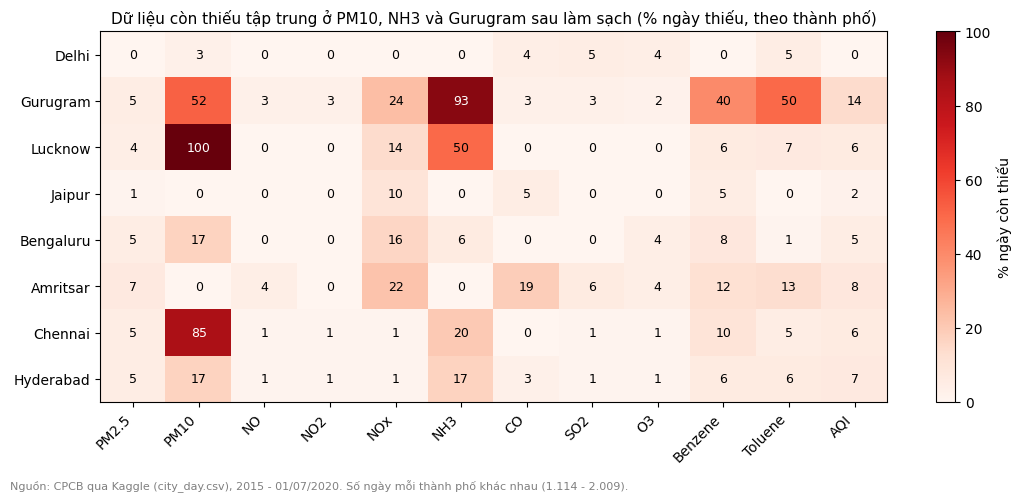

In [11]:
# Biểu đồ: % thiếu còn lại sau làm sạch
fig, ax = plt.subplots(figsize=(11, 5))
data = miss.values
im = ax.imshow(data, cmap="Reds", vmin=0, vmax=100, aspect="auto")
ax.set_xticks(range(data.shape[1])); ax.set_xticklabels(miss.columns, rotation=45, ha="right")
ax.set_yticks(range(data.shape[0])); ax.set_yticklabels(miss.index)
for i in range(data.shape[0]):
    for j in range(data.shape[1]):
        v = data[i, j]
        ax.text(j, i, f"{v:.0f}", ha="center", va="center",
                color="white" if v > 55 else "black", fontsize=9)
ax.set_title("Dữ liệu còn thiếu tập trung ở PM10, NH3 và Gurugram sau làm sạch (% ngày thiếu, theo thành phố)", fontsize=11)
fig.colorbar(im, ax=ax, label="% ngày còn thiếu")
fig.text(0.01, 0.01, "Nguồn: CPCB qua Kaggle (city_day.csv), 2015 - 01/07/2020. Số ngày mỗi thành phố khác nhau (1.114 - 2.009).",
         fontsize=8, color="gray")
fig.tight_layout(rect=(0, 0.03, 1, 1))
fig.savefig(FIG / "missing_after_cleaning_8cities.png", dpi=150)
plt.show()

## Kết quả

- `data/processed/air_quality_8cities.csv`: bảng gộp 8 thành phố, dùng cho `03_eda`.
- `reports/cleaning_summary_8cities.csv`: thành phố × cột, mỗi con số cân đối được.
- `reports/suspect_points_8cities.csv`: mọi điểm đã xét là nghi lỗi hay không, kèm giá trị gốc và bằng chứng.
- Bằng chứng đằng sau từng quyết định (so sánh chiến lược điền, so sánh phương pháp outlier, điều tra từng điểm) nằm ở `02_cleaning_evidence.ipynb`.
